# 02 EDA and preprocessing (Part B1)

What the data looks like, what that means for modelling, and two preprocessing decisions: how to treat loans split across lenders, and what the Train/Test customer overlap means for validation. Leaky columns from Section 1 are excluded from every plot that informs feature choices.

In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import set_seed, FIGURES
from src.data import load_rows, to_loans
set_seed(); sns.set_theme(style="whitegrid", font_scale=0.9)
RED, BLUE = "tab:red", "tab:blue"

def save(name):
    plt.tight_layout(); plt.savefig(FIGURES / f"02_{name}.png", dpi=200); plt.show()

rows, te_rows = load_rows("train"), load_rows("test")
loans, te_loans = to_loans(rows), to_loans(te_rows)
ke_te, gh_te = te_loans[te_loans.country_id == "Kenya"], te_loans[te_loans.country_id == "Ghana"]
pd.DataFrame({"rows": [len(rows), len(te_rows)], "loans": [len(loans), len(te_loans)],
              "customers": [rows.customer_id.nunique(), te_rows.customer_id.nunique()]}, index=["Train", "Test"])

,rows,loans,customers
Train,68654,66520,6540
Test,18594,17067,4962


In [2]:
print("Missing values in Train:", int(rows.isna().sum().sum()), "| in Test:", int(te_rows.isna().sum().sum()))
print("Duplicate row IDs:", int(rows.ID.duplicated().sum()))

Missing values in Train: 0 | in Test: 0
Duplicate row IDs: 0


## 2.1 Class balance

From here on the unit is the **loan** (see 2.6). The default rate per loan is **1.63%** (1,082 of 66,520). The 1.83% quoted in the workplan is per *row*, inflated because the riskier co-funded loans are counted twice. A model that approves everyone is 98.4% accurate and useless. Accuracy is not reported anywhere in this project; PR-AUC, recall and precision are.

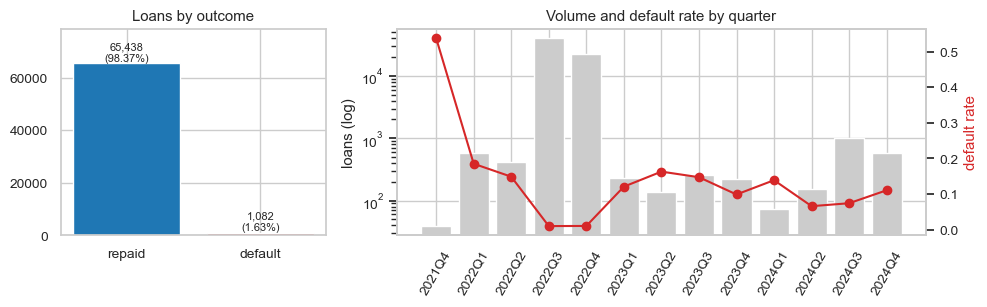

disbursement_date,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
loans,39.000,578.000,417.000,40380.00,22447.00,232.000,135.000,258.000,223.000,72.000,152.000,999.000,588.000
default_rate,0.538,0.185,0.149,0.01,0.01,0.121,0.163,0.147,0.099,0.139,0.066,0.074,0.111


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1, 2]})
vc = loans.target.value_counts().sort_index()
axes[0].bar(["repaid", "default"], vc.values, color=[BLUE, RED])
for i, v in enumerate(vc.values): axes[0].text(i, v, f"{v:,}\n({v / len(loans):.2%})", ha="center", va="bottom", fontsize=8)
axes[0].set(title="Loans by outcome", ylim=(0, vc.max() * 1.2))
q = loans.groupby(loans.disbursement_date.dt.to_period("Q")).target.agg(["size", "mean"])
axes[1].bar(q.index.astype(str), q["size"], color="0.8"); axes[1].set_yscale("log"); axes[1].set_ylabel("loans (log)")
ax2 = axes[1].twinx(); ax2.plot(q.index.astype(str), q["mean"], "o-", color=RED); ax2.set_ylabel("default rate", color=RED); ax2.grid(False)
axes[1].set_title("Volume and default rate by quarter"); axes[1].tick_params(axis="x", rotation=60)
save("class_balance")
q.rename(columns={"size": "loans", "mean": "default_rate"}).T.round(3)

94% of loans were disbursed in 2022 Q3 to Q4, when the default rate was about 1%. In the thinner quarters before and after, it runs at 5 to 50%. **The default rate is not stationary**, so a random split mixes regimes and a temporal split puts very few, very different loans in the test window (Section 4).

## 2.2 Loan amounts

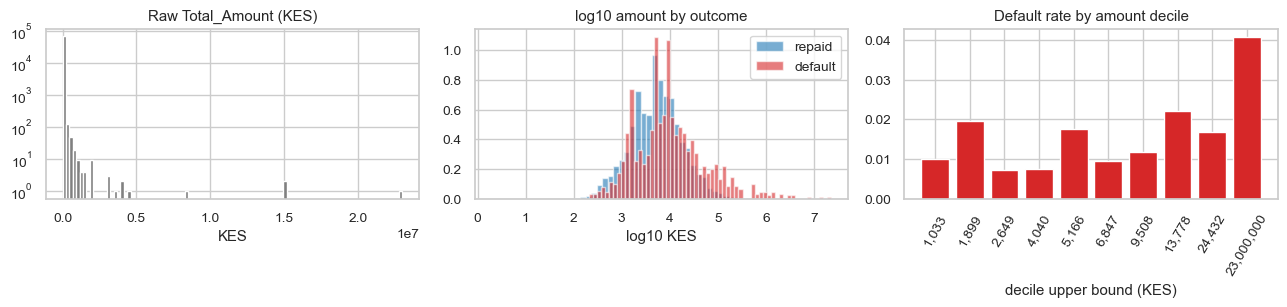

,count,mean,std,min,1%,25%,50%,75%,99%,max
Total_Amount (KES),66520.0,13588.0,137427.0,2.0,310.0,2259.0,5166.0,11188.0,105000.0,23000000.0


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(loans.Total_Amount, bins=100, color="0.5"); axes[0].set(title="Raw Total_Amount (KES)", yscale="log", xlabel="KES")
for t, c in [(0, BLUE), (1, RED)]:
    axes[1].hist(np.log10(loans.loc[loans.target == t, "Total_Amount"]), bins=60, density=True, alpha=.6, color=c, label=["repaid", "default"][t])
axes[1].set(title="log10 amount by outcome", xlabel="log10 KES"); axes[1].legend()
band = pd.qcut(loans.Total_Amount, 10)
br = loans.groupby(band, observed=True).target.mean()
axes[2].bar(range(10), br.values, color=RED); axes[2].set_xticks(range(10), [f"{b.right:,.0f}" for b in br.index], rotation=60)
axes[2].set(title="Default rate by amount decile", xlabel="decile upper bound (KES)")
save("amounts")
loans.Total_Amount.describe(percentiles=[.01, .25, .5, .75, .99]).round(0).to_frame("Total_Amount (KES)").T

The amount spans 2 to 23,000,000 KES, a skew of more than six orders of magnitude, so models use `log1p(Total_Amount)`. The default rate is noisy and not monotonic across the first nine deciles (0.7 to 2.2%) and doubles to 4% in the top decile, so size matters mainly at the large end and is best combined with term and type, which drive the big loans. The 48 loans above 1M KES are mostly long-term Type_4 and Type_23 loans; they are genuine products, not data errors, so they are kept and the log scale handles them.

## 2.3 Duration

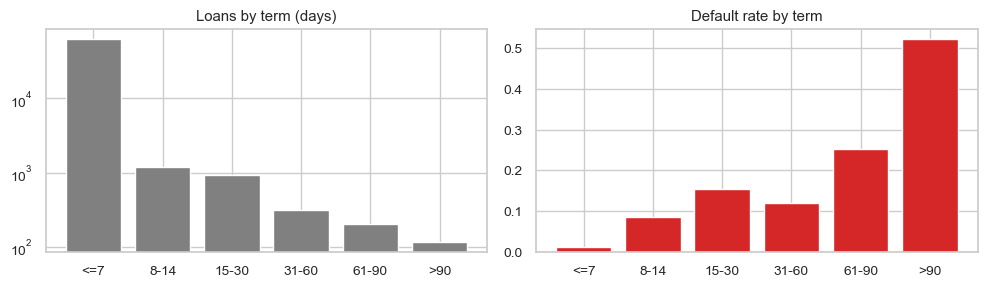

96% of loans are 7-day loans


duration,<=7,8-14,15-30,31-60,61-90,>90
loans,63752.000,1203.000,925.000,317.00,202.000,117.000
default_rate,0.011,0.085,0.155,0.12,0.252,0.521


In [5]:
dur = loans.duration
bucket = pd.cut(dur, [0, 7, 14, 30, 60, 90, 400], labels=["<=7", "8-14", "15-30", "31-60", "61-90", ">90"])
tab = loans.groupby(bucket, observed=True).target.agg(["size", "mean"]).rename(columns={"size": "loans", "mean": "default_rate"})
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].bar(tab.index.astype(str), tab.loans, color="0.5"); axes[0].set(yscale="log", title="Loans by term (days)")
axes[1].bar(tab.index.astype(str), tab.default_rate, color=RED); axes[1].set(title="Default rate by term")
save("duration")
print(f"{(dur == 7).mean():.0%} of loans are 7-day loans")
tab.round(3).T

Kenya is overwhelmingly a 7-day market (96% of loans; the workplan's "75%" was the 75th percentile, which is also 7 days), and longer terms default far more often. Ghana Test loans average about 36 days (Section 10), which is the *thin, high-risk* part of the Kenyan data, so the Kenyan model has little evidence where Ghana needs it most.

## 2.4 Loan types

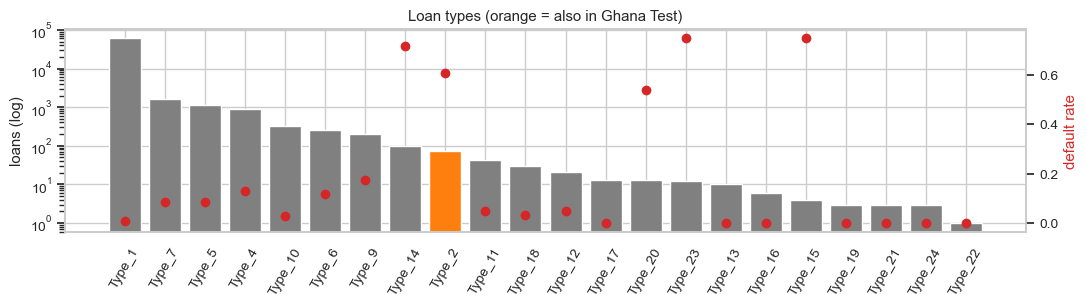

Type_1 is 93% of loans; 11 types have fewer than 30 loans
Ghana Test types: {'Type_3': 1782, 'Type_2': 274, 'Type_8': 28} | unseen in Train: ['Type_3', 'Type_8']


,loans,default_rate,median_amount,median_days,in_ghana_test
loan_type,,,,,
Type_1,61723,0.008,4930.0,7.0,False
Type_7,1646,0.084,5906.0,7.0,False
Type_5,1166,0.083,18000.0,14.0,False
Type_4,872,0.128,30000.0,30.0,False
Type_10,319,0.028,101347.0,29.0,False
Type_6,255,0.118,4490.0,7.0,False
Type_9,205,0.176,20200.0,30.0,False
Type_14,99,0.717,10000.0,30.0,False
Type_2,74,0.608,150000.0,136.0,True


In [6]:
lt = loans.groupby("loan_type").agg(loans=("target", "size"), default_rate=("target", "mean"),
                                    median_amount=("Total_Amount", "median"), median_days=("duration", "median"))
lt["in_ghana_test"] = lt.index.isin(gh_te.loan_type)
lt = lt.sort_values("loans", ascending=False)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(lt.index, lt.loans, color=["tab:orange" if g else "0.5" for g in lt.in_ghana_test]); ax.set_yscale("log")
ax2 = ax.twinx(); ax2.plot(lt.index, lt.default_rate, "o", color=RED); ax2.set_ylabel("default rate", color=RED); ax2.grid(False)
ax.set(title="Loan types (orange = also in Ghana Test)", ylabel="loans (log)"); ax.tick_params(axis="x", rotation=60)
save("loan_types")
print(f"Type_1 is {lt.loans.iloc[0] / len(loans):.0%} of loans; {(lt.loans < 30).sum()} types have fewer than 30 loans")
print("Ghana Test types:", gh_te.loan_type.value_counts().to_dict(), "| unseen in Train:", sorted(set(gh_te.loan_type) - set(loans.loan_type)))
lt.round(3)

22 types, one of which (Type_1) is 93% of loans; 11 have fewer than 30 loans, so their default rates are noise. **Preprocessing:** group types with fewer than 30 training loans into `Other`, and map any unseen type (Ghana's Type_3 and Type_8) to an explicit `Unknown` level rather than letting the encoder fail or silently reuse `Other`.

## 2.5 Lenders

In [7]:
le = pd.concat({
    "Train loans": loans.lender_id.value_counts(),
    "Train default rate": loans.groupby("lender_id").target.mean().round(3),
    "Kenya Test loans": ke_te.lender_id.value_counts(),
    "Ghana Test loans": gh_te.lender_id.value_counts(),
}, axis=1).fillna(0)
le.astype({c: int for c in le.columns if "loans" in c})

,Train loans,Train default rate,Kenya Test loans,Ghana Test loans
lender_id,,,,
267278,62713,0.010,14142,0
251804,3348,0.090,754,0
267277,271,0.295,46,0
245684,188,0.415,41,84
296542,0,0.000,0,1802
297182,0,0.000,0,111
296540,0,0.000,0,80
297183,0,0.000,0,7


Lender 267278 carries 94% of Kenyan loans at a 1.2% default rate; the other three default at 9 to 41%. `lender_id` is therefore a strong feature, but it largely encodes *which lender's book* a loan is in rather than the borrower. Ghana Test uses five lenders and only 245684 (188 Kenyan loans, 41% default) is seen in Train. A Kenyan lender effect cannot be transferred to unknown Ghanaian lenders (Section 10).

## 2.6 Decision: loans split across lenders

In [8]:
split = loans[loans.n_lenders == 2]
print(f"{len(split):,} Train loans ({len(split) / len(loans):.1%}) are co-funded by two lenders:", split.lenders.value_counts().to_dict())
pd.DataFrame({"loans": [len(split), (loans.n_lenders == 1).sum()],
              "default_rate": [split.target.mean(), loans.loc[loans.n_lenders == 1, "target"].mean()]},
             index=["co-funded", "single lender"]).round(4)

2,134 Train loans (3.2%) are co-funded by two lenders: {'251804+267278': 2127, '245684+251804': 7}


,loans,default_rate
co-funded,2134,0.0834
single lender,64386,0.0140


In [9]:
# Where the two halves of each co-funded loan ended up
allrows = pd.concat([rows.assign(split="Train"), te_rows.assign(split="Test")])
halves = allrows.groupby("tbl_loan_id").filter(lambda g: len(g) == 2).groupby("tbl_loan_id").split.agg(lambda s: " + ".join(sorted(s)))
halves.value_counts().to_frame("co-funded loans")

,co-funded loans
split,
Train + Train,2134
Test + Test,1455
Test + Train,920


**Facts.** Every loan-level field (customer, amount, type, dates, duration) is identical across a loan's two rows. Co-funded loans default at 8.3% against 1.4%. Zindi split by *row*, so for 920 loans one lender's row (with its label) is in Train and the other is in Test.

**Decision: model at loan level.** `src/data.py::to_loans` collapses each loan to one row: shares summed, primary lender = largest share, `n_lenders` kept as a feature, target = 1 if any half defaulted (2 conflicts). Predictions are broadcast back to row IDs for any submission.

*Why:* at row level a co-funded loan counts twice, so the riskiest segment is over-weighted, and CV could put one half of a loan in training and its twin in validation, a near-perfect leak. Copying a Train label onto the 920 matching Test rows would raise a leaderboard score, but it is not available for a real new application, so we do not do it.

## 2.7 Disbursement dates over time

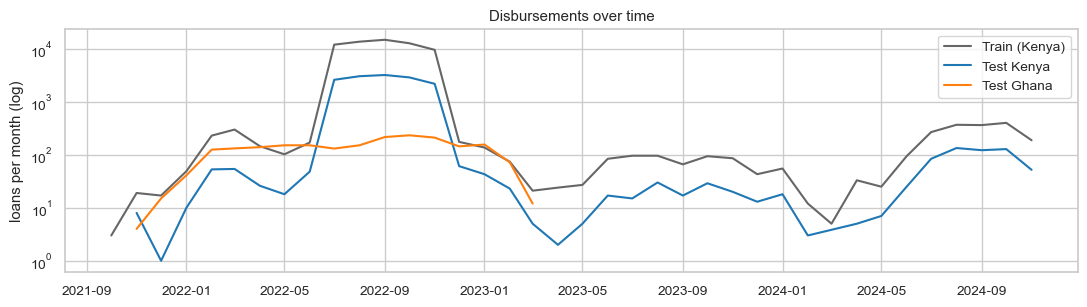

Kenya Test share of Kenyan loans per quarter: min 0.15, max 0.25, overall 0.18


In [10]:
fig, ax = plt.subplots(figsize=(11, 3.2))
for df, lab, c in [(loans, "Train (Kenya)", "0.4"), (ke_te, "Test Kenya", BLUE), (gh_te, "Test Ghana", "tab:orange")]:
    m = df.groupby(df.disbursement_date.dt.to_period("M")).size()
    ax.plot(m.index.to_timestamp(), m.values, label=lab, color=c)
ax.set(yscale="log", ylabel="loans per month (log)", title="Disbursements over time"); ax.legend()
save("dates")
q = lambda d: d.groupby(d.disbursement_date.dt.to_period("Q")).size()
share = (q(ke_te) / (q(ke_te) + q(loans))).dropna()
print(f"Kenya Test share of Kenyan loans per quarter: min {share.min():.2f}, max {share.max():.2f}, overall {len(ke_te) / (len(ke_te) + len(loans)):.2f}")

Kenyan Test loans are spread across the same months as Train in a roughly constant proportion (15 to 25% each quarter, 18% overall): **the Zindi Kenya split is random, not temporal**. Ghana Test runs Nov 2021 to Mar 2023 with no Ghanaian training data at all. The 2023 to 2024 gap in Kenyan volume, and the jump in default rate after it, is the regime change that a temporal validation has to face.

## 2.8 Decision: Train/Test customer overlap

In [11]:
seen = te_loans.customer_id.isin(loans.customer_id)
pd.DataFrame({"Test customers": te_loans.groupby("country_id").customer_id.nunique(),
              "also in Train": te_loans[seen].groupby("country_id").customer_id.nunique(),
              "share of Test loans with seen customer": seen.groupby(te_loans.country_id).mean().round(3)}).fillna(0)

,Test customers,also in Train,share of Test loans with seen customer
country_id,,,
Ghana,446,0.0,0.000
Kenya,4516,4306.0,0.985


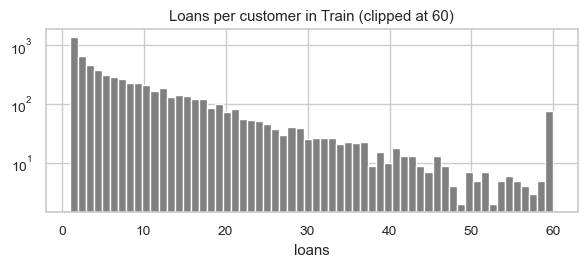

Median 6 loans per customer; 15.5% of customers default at least once
Customer's first loan in the data is labelled 'New Loan' for only 6.6% of customers -> history began before Oct 2021


In [12]:
per_cust = loans.groupby("customer_id").agg(loans=("target", "size"), ever_default=("target", "max"))
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(per_cust.loans.clip(upper=60), bins=60, color="0.5"); ax.set(title="Loans per customer in Train (clipped at 60)", xlabel="loans", yscale="log")
save("loans_per_customer")
print(f"Median {per_cust.loans.median():.0f} loans per customer; {per_cust.ever_default.mean():.1%} of customers default at least once")
first = loans.sort_values("disbursement_date").groupby("customer_id").head(1)
print(f"Customer's first loan in the data is labelled 'New Loan' for only {(first.New_versus_Repeat == 'New Loan').mean():.1%} of customers -> history began before Oct 2021")

**Facts.** 4,306 of 4,962 Test customers (87%) also appear in Train, every one of them Kenyan; Ghanaian Test customers are all new. Customers have a median of 6 loans, so a customer's other loans say a lot about the next one.

**Decision.**
1. *Validation must not share customers between folds* (GroupKFold on `customer_id`, Section 4). Otherwise the model memorises borrowers and the score answers "how well do we re-score customers we have already seen", which flatters Kenya and says nothing about Ghana, where every customer is new.
2. *Borrower history is a legitimate feature*, built only from a customer's earlier loans whose due date had passed (Section 1). For a Kenyan Test customer, their Train loans are their history, exactly as NkwaPay would have it in production.
3. Report results for **seen** and **new** customers separately, because the Kenyan Test score is dominated by seen customers and Ghana is entirely new ones.

The data window also starts mid-history: most customers' first loan in the data is already a Repeat loan, so "past loan count" from this data undercounts true history. Keep `New_versus_Repeat` as a feature alongside the counts.

## Summary for later sections

| Finding | Consequence |
|---|---|
| 1.63% of loans default (1.83% per row), rate shifts strongly by quarter | PR-AUC not accuracy; temporal split is hard but necessary |
| Amount skew of 10^6 | `log1p(Total_Amount)` |
| 96% 7-day loans; longer terms riskier (52% default above 90 days) | Duration is a key feature; Ghana's long loans are out of distribution |
| 22 loan types, 13 rare; 2 Ghana types unseen | Group rare to `Other`, unseen to `Unknown` |
| Lender dominates risk; 4 of 5 Ghana lenders unseen | Lender effect will not transfer; flag in Part C |
| 2,134 co-funded loans, twins straddle Train/Test | Model at loan level (`src/data.py`), `n_lenders` feature |
| 87% of Test customers seen in Train | GroupKFold on customer; report seen vs new customers |
| No missing values | No imputation needed for raw columns; history features will need a value for first loans |